# 07 - Tuning XGBoost by hand

**Who worked on this:** Mohammed ABuQamar

**Why this notebook?** FLAML (05) found that boosting beats bagging and that XGBoost is the best family. AutoML gave us a good model fast, but it hides *why*. Here we tune the winner ourselves, with experiments we can explain.

**How the three-way split is used**
| set | what we do with it here |
|---|---|
| train | fit the trees |
| validation | **early stopping** (stop adding trees when validation error stops improving), choosing the objective, features and hyperparameters |
| test | scored **once**, at the very end, for the final model only |

**Experiments, in this order** (each one answers one question):
1. **Complexity curves**: is the model underfitting or overfitting? (bias-variance chapter)
2. **Objective**: our target is a *count* and our metric is MAE. Does a different loss function help?
3. **Features**: does the station `cluster` from 06 help? Is `year` helping or hurting?
4. **Random search** of the hyperparameters, using the best objective and features
5. **Final model**: refit, test score once, error analysis

To keep the experiments fast we train them on a random sample of the training rows (`EXP_ROWS`). The final model uses all rows.

In [1]:
import os
THREADS = 4          # lower to 1 if you get crashes; must run before numpy/pandas are imported (restart the kernel)
for var in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[var] = str(THREADS)

In [2]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append(".")
from src.features import (load_demand, time_split, regression_metrics, save_metrics, load_metrics,
                          add_cluster_feature, load_cluster_mapping, FEATURES, TARGET)
sns.set_theme(style="whitegrid")

import xgboost as xgb
print("xgboost", xgb.__version__)

EXP_ROWS = 3_000_000       # rows used for experiments 1-4 (lower = faster)
N_ITER = 12                # random search: number of hyperparameter combinations
SEED = 42

df = load_demand()
mapping = load_cluster_mapping()
if mapping:
    df = add_cluster_feature(df, mapping)
    print("cluster feature available:", df["cluster"].nunique(), "values")
else:
    print("no models/station_clusters.csv - run 06 first to test the cluster feature")
STATIONS = list(df["station"].cat.categories)
train, valid, test = time_split(df)
sample = train.sample(min(EXP_ROWS, len(train)), random_state=SEED)
print(f"train {len(train):,} (experiments use {len(sample):,}) | valid {len(valid):,} | test {len(test):,}")

def to_input(d, feats):
    X = d[feats].copy()
    if "station" in feats:
        X["station"] = X["station"].cat.codes      # integer code; trees are fine with it (lat/lng identify the station too)
    return X.astype("float32")

xgboost 2.1.4
cluster feature available: 5 values
train 6,925,801 (experiments use 3,000,000) | valid 865,701 | test 876,000


A helper that trains one XGBoost model with **early stopping on the validation set** and returns its validation scores. Everything below is built on it. `n_estimators` is set high on purpose: early stopping decides how many trees are really used (`best_iteration`).

Some transformations change the target (`log1p`), so predictions are transformed back before scoring. Scores are always in trips per hour. (For the `log1p` variant, early stopping watches the error on the log scale, which is slightly different from the MAE we report.)

In [3]:
BASE = dict(max_depth=8, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
            min_child_weight=5, reg_lambda=5.0)

def fit_eval(params, feats, rows=None, objective="reg:squarederror", log_target=False,
             eval_train=None, max_trees=3000, patience=50):
    rows = sample if rows is None else rows
    t0 = time.time()
    f = np.log1p if log_target else (lambda v: v)
    inv = np.expm1 if log_target else (lambda v: v)
    Xtr, ytr = to_input(rows, feats), rows[TARGET].astype("float32")
    Xva, yva = to_input(valid, feats), valid[TARGET].astype("float32")
    model = xgb.XGBRegressor(objective=objective, n_estimators=max_trees, early_stopping_rounds=patience,
                             tree_method="hist", n_jobs=THREADS, random_state=SEED, eval_metric="mae", **params)
    evals = [(Xva, f(yva))] if eval_train is None else [eval_train, (Xva, f(yva))]
    model.fit(Xtr, f(ytr), eval_set=evals, verbose=False)
    pred = np.clip(inv(model.predict(Xva, iteration_range=(0, model.best_iteration + 1))), 0, None)
    m = regression_metrics(yva, pred)
    return model, {**m, "best_iter": model.best_iteration + 1, "seconds": round(time.time() - t0)}

model, r = fit_eval(BASE, FEATURES)
print("reference run:", {k: round(v, 3) for k, v in r.items()})

reference run: {'MAE': 4.181, 'RMSE': 6.628, 'R2': 0.661, 'best_iter': 311, 'seconds': 168}


## 1. Complexity curves: underfitting or overfitting?
The Models chapter's picture: as a model gets more complex, the **training** error keeps falling, but the **validation** error falls and then rises again. The best model sits at the bottom of the validation curve (the "sweet spot"): left of it the model underfits (high bias), right of it it overfits (high variance).

**Curve A - number of trees.** One run, errors recorded after every tree.

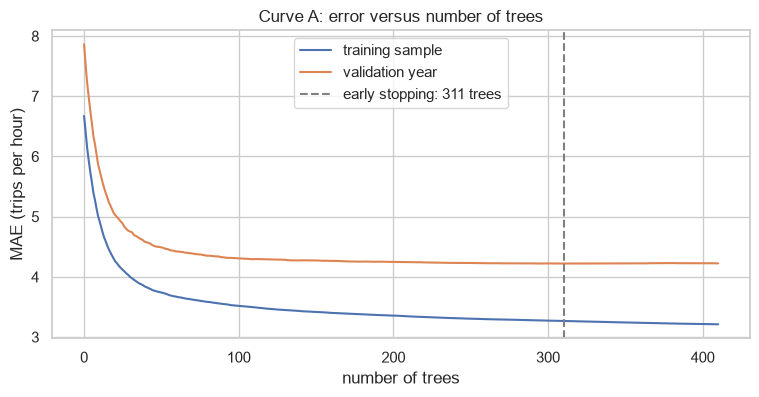

In [4]:
train_part = sample.sample(min(500_000, len(sample)), random_state=SEED)
eval_train = (to_input(train_part, FEATURES), train_part[TARGET].astype("float32"))
model, r = fit_eval(BASE, FEATURES, eval_train=eval_train, patience=100)
hist = model.evals_result()
plt.figure(figsize=(9, 4))
plt.plot(hist["validation_0"]["mae"], label="training sample")
plt.plot(hist["validation_1"]["mae"], label="validation year")
plt.axvline(model.best_iteration, color="grey", ls="--", label=f"early stopping: {model.best_iteration + 1} trees")
plt.xlabel("number of trees"); plt.ylabel("MAE (trips per hour)"); plt.legend()
plt.title("Curve A: error versus number of trees"); plt.show()

**Curve B - depth of the trees.** Deeper trees can model more complicated patterns (more complexity). Each depth is trained with early stopping.

,train_MAE,valid_MAE,trees
max_depth,,,
2,4.241,4.916,1722
3,3.920,4.582,977
4,3.693,4.432,870
6,3.374,4.272,625
8,3.227,4.181,311
10,3.099,4.121,180
12,2.997,4.125,113


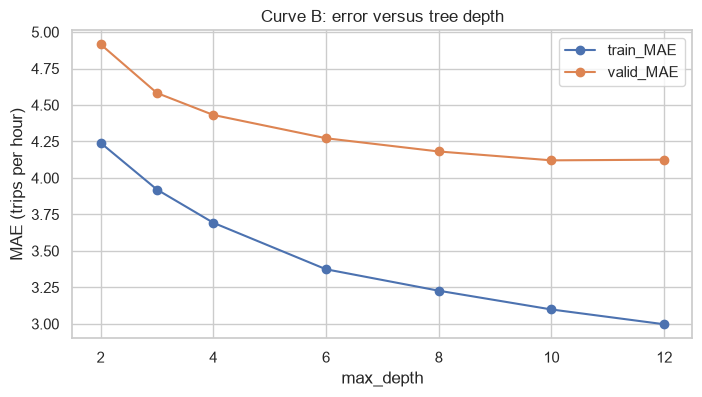

In [5]:
depth_rows = []
for depth in [2, 3, 4, 6, 8, 10, 12]:
    m, r = fit_eval({**BASE, "max_depth": depth}, FEATURES)
    tr_pred = np.clip(m.predict(to_input(train_part, FEATURES), iteration_range=(0, m.best_iteration + 1)), 0, None)
    depth_rows.append({"max_depth": depth, "train_MAE": regression_metrics(train_part[TARGET], tr_pred)["MAE"],
                       "valid_MAE": r["MAE"], "trees": r["best_iter"]})
depth_df = pd.DataFrame(depth_rows).set_index("max_depth")
display(depth_df.round(3))
depth_df[["train_MAE", "valid_MAE"]].plot(marker="o", figsize=(8, 4), title="Curve B: error versus tree depth")
plt.ylabel("MAE (trips per hour)"); plt.show()

**Reading the curves (rewrite in your own words):** where is the validation minimum? Is the gap between training and validation error growing with depth (overfitting)? Does our reference depth of 8 sit near the sweet spot, or should the random search look at lower or higher values?

## 2. Which objective (loss function)?
Our target is a **count** (trips per hour, never negative, skewed to the right) and we report **MAE**. The default loss, squared error, aims at the *mean* and punishes big misses hardest. Alternatives:
- `reg:absoluteerror` aims directly at the MAE (the *median*)
- `count:poisson` is built for counts: predictions can never be negative, and the error scales with the level of demand
- `log1p` target: squeeze the skew with a log transform (Data augmentation chapter: skewed data), predict, and transform back

In [6]:
OBJECTIVES = {
    "squared error (default)":     dict(objective="reg:squarederror"),
    "absolute error (median)":     dict(objective="reg:absoluteerror"),
    "poisson (counts)":            dict(objective="count:poisson"),
    "log1p target + squared err":  dict(objective="reg:squarederror", log_target=True),
}
rows = []
for name, kw in OBJECTIVES.items():
    _, r = fit_eval(BASE, FEATURES, **kw)
    rows.append({"objective": name, **r})
obj_df = pd.DataFrame(rows).set_index("objective")
display(obj_df.round(3))
BEST_OBJ = obj_df["MAE"].idxmin()
print("best on validation MAE:", BEST_OBJ)

,MAE,RMSE,R2,best_iter,seconds
objective,,,,,
squared error (default),4.181,6.628,0.661,311,150
absolute error (median),4.145,6.656,0.658,1253,4116
poisson (counts),4.094,6.579,0.666,542,286
log1p target + squared err,4.501,7.421,0.575,309,146


best on validation MAE: poisson (counts)


If another objective wins on MAE but loses clearly on RMSE, that is a trade-off, not an improvement: it just means the model targets a different part of the distribution. Mention it if it happens. The code picks the lowest validation **MAE**, because that is the metric we chose to report.

## 3. Which features?
Controlled experiment: same model, same settings, only the feature list changes.
- **+ cluster**: station type from 06 (unsupervised learning). Does it add information beyond the station itself?
- **- year**: tree models cannot extrapolate. If demand grows every year, `year` makes the model think the test year looks like the last year it saw. Without it the model cannot tell years apart at all. Which is worse?

In [7]:
FEATURE_SETS = {"all features (05)": FEATURES, "- year": [f for f in FEATURES if f != "year"]}
if "cluster" in df.columns:
    FEATURE_SETS["+ cluster"] = FEATURES + ["cluster"]
    FEATURE_SETS["+ cluster, - year"] = [f for f in FEATURES + ["cluster"] if f != "year"]
rows = []
for name, feats in FEATURE_SETS.items():
    _, r = fit_eval(BASE, feats, **OBJECTIVES[BEST_OBJ])
    rows.append({"features": name, **r})
feat_df = pd.DataFrame(rows).set_index("features")
display(feat_df.round(3))
BEST_FEATS = FEATURE_SETS[feat_df["MAE"].idxmin()]
print("best on validation MAE:", feat_df["MAE"].idxmin(), "->", BEST_FEATS)

,MAE,RMSE,R2,best_iter,seconds
features,,,,,
all features (05),4.094,6.579,0.666,542,281
- year,4.844,7.724,0.540,619,307
+ cluster,4.095,6.582,0.666,628,326
"+ cluster, - year",4.841,7.719,0.540,507,262


best on validation MAE: all features (05) -> ['station', 'hour', 'dayofweek', 'month', 'year', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'lat', 'lng']


**Reading the table (rewrite):** did `cluster` help? If the gain is tiny, say so honestly: stations already carry their identity through lat/lng, so the cluster only adds a group label. "We tried it and it did not help" is a valid result, as long as it is measured. Differences in the third decimal are within noise.

## 4. Random search over the hyperparameters
Unlike a grid, random search tries random combinations, which covers important parameters better for the same number of runs. Every combination is trained with early stopping and scored on the validation year. Settings:
- `max_depth`, `min_child_weight`: how complex a single tree may be
- `learning_rate`: smaller steps need more trees but usually generalise better
- `subsample`, `colsample_bytree`: train each tree on a random part of rows / columns (like bagging inside boosting)
- `reg_lambda`: penalty on large leaf values (XGBoost's regularisation)

In [8]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler

space = {"max_depth": randint(4, 13), "learning_rate": loguniform(0.02, 0.2),
         "min_child_weight": randint(1, 50), "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(0.1, 50)}
search = []
for i, p in enumerate(ParameterSampler(space, n_iter=N_ITER, random_state=SEED)):
    p = {k: (float(v) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in p.items()}
    _, r = fit_eval(p, BEST_FEATS, **OBJECTIVES[BEST_OBJ])
    search.append({**p, **r}); print(f"{i + 1}/{N_ITER} valid MAE {r['MAE']:.3f} ({r['best_iter']} trees, {r['seconds']}s)")
search_df = pd.DataFrame(search).sort_values("MAE")
search_df.to_csv("models/xgb_random_search.csv", index=False)
display(search_df.head(5).round(3))
BEST_PARAMS = {k: search_df.iloc[0][k] for k in space}
BEST_PARAMS = {k: (int(v) if k in ("max_depth", "min_child_weight") else float(v)) for k, v in BEST_PARAMS.items()}
print("best parameters:", BEST_PARAMS)

1/12 valid MAE 4.086 (217 trees, 161s)
2/12 valid MAE 4.107 (511 trees, 250s)
3/12 valid MAE 4.109 (290 trees, 176s)
4/12 valid MAE 4.080 (292 trees, 234s)
5/12 valid MAE 4.118 (634 trees, 278s)
6/12 valid MAE 4.097 (687 trees, 347s)
7/12 valid MAE 4.106 (136 trees, 127s)
8/12 valid MAE 4.084 (1065 trees, 667s)
9/12 valid MAE 4.078 (415 trees, 244s)
10/12 valid MAE 4.118 (1394 trees, 632s)
11/12 valid MAE 4.087 (475 trees, 298s)
12/12 valid MAE 4.102 (397 trees, 319s)


,colsample_bytree,learning_rate,max_depth,min_child_weight,reg_lambda,subsample,MAE,RMSE,R2,best_iter,seconds
8,0.591,0.114,9,42,3.406,0.613,4.078,6.535,0.670,415,244
3,0.652,0.067,12,49,2.608,0.760,4.080,6.541,0.670,292,234
7,0.720,0.026,11,47,0.294,0.756,4.084,6.558,0.668,1065,667
0,0.687,0.179,11,21,0.264,0.662,4.086,6.563,0.668,217,161
10,0.785,0.066,11,21,1.120,0.709,4.087,6.580,0.666,475,298


best parameters: {'max_depth': 9, 'learning_rate': 0.11386530295389598, 'min_child_weight': 42, 'subsample': 0.6125253169822235, 'colsample_bytree': 0.5911180438940311, 'reg_lambda': 3.4056981719938784}


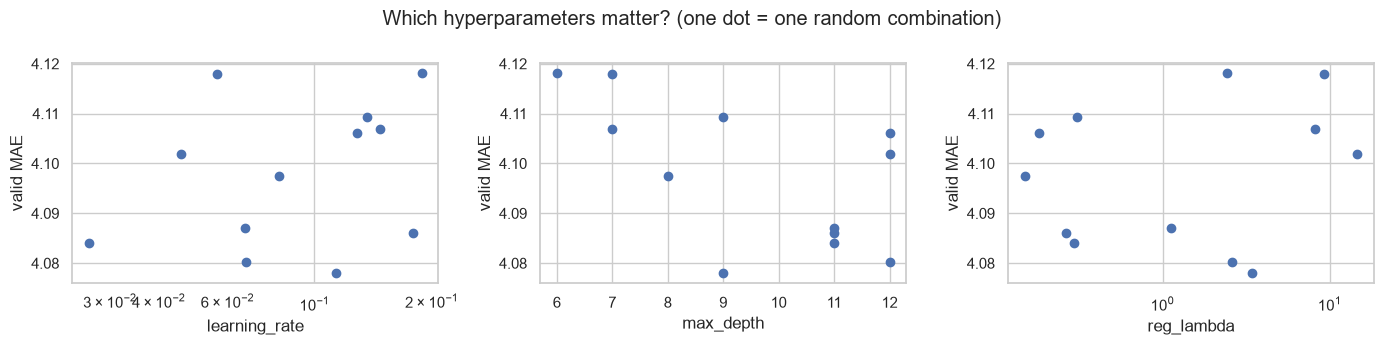

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ["learning_rate", "max_depth", "reg_lambda"]):
    a.scatter(search_df[col], search_df["MAE"]); a.set_xlabel(col); a.set_ylabel("valid MAE")
    if col != "max_depth": a.set_xscale("log")
plt.suptitle("Which hyperparameters matter? (one dot = one random combination)"); plt.tight_layout(); plt.show()

## 5. The final model
1. Train on **all** training rows with the best settings, early stopping on the validation year. This gives the **validation score** we use for ranking.
2. Refit on **train + validation** with the same settings and `1.1 x` the number of trees (there is about 10% more data), no early stopping. This model sees the most recent year. It gets the **test score**, once.

In [10]:
kw = OBJECTIVES[BEST_OBJ]
final_va, r = fit_eval(BEST_PARAMS, BEST_FEATS, rows=train, **kw)
valid_metrics = {k: r[k] for k in ("MAE", "RMSE", "R2")}
n_trees = int(r["best_iter"] * 1.1)
print("validation:", {k: round(v, 3) for k, v in valid_metrics.items()}, "| trees:", r["best_iter"], "| FLAML (05) for comparison: see table below")

log_target = kw.get("log_target", False)
f = np.log1p if log_target else (lambda v: v)
inv = np.expm1 if log_target else (lambda v: v)
trval = pd.concat([train, valid])
final = xgb.XGBRegressor(objective=kw["objective"], n_estimators=n_trees, tree_method="hist", n_jobs=THREADS,
                         random_state=SEED, **BEST_PARAMS)
final.fit(to_input(trval, BEST_FEATS), f(trval[TARGET].astype("float32")), verbose=False)
pred = np.clip(inv(final.predict(to_input(test, BEST_FEATS))), 0, None)
test_metrics = regression_metrics(test[TARGET], pred)
print("test      :", {k: round(v, 3) for k, v in test_metrics.items()})

save_metrics("xgboost_tuned", valid_metrics, test_metrics, where="local",
             note=f"objective={BEST_OBJ}; features={len(BEST_FEATS)}; trees={n_trees}; {BEST_PARAMS}")
load_metrics()[["valid_MAE", "valid_RMSE", "valid_R2", "test_MAE", "test_RMSE", "test_R2", "where"]].round(3)

validation: {'MAE': 4.069, 'RMSE': 6.521, 'R2': 0.672} | trees: 510 | FLAML (05) for comparison: see table below
test      : {'MAE': 4.208, 'RMSE': 6.625, 'R2': 0.689}


,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2,where
xgboost_tuned,4.068896,6.520625,0.671859,4.208441,6.62485,0.688896,local
flaml_xgboost,4.092188,6.527758,0.671141,4.226107,6.626563,0.688735,local
baseline_seasonal_naive,4.816103,7.624048,0.551406,5.205211,8.409907,0.498655,local
baseline_last_year,5.075872,7.867899,0.522251,5.447443,8.278868,0.514157,local
linear_ridge,5.937776,9.137574,0.355617,6.322705,9.51637,0.358057,local
global_mean,8.359283,11.477536,-0.016669,8.935258,11.878421,-0.000165,local


In [11]:
import joblib
Path("models").mkdir(exist_ok=True)
# Save the underlying booster, not the scikit-learn wrapper: it does not depend on the scikit-learn version,
# and the API can load it with plain xgboost (xgb.Booster().load_model) and predict from a DMatrix.
final.get_booster().save_model("models/xgb_tuned.json")
joblib.dump({"features": BEST_FEATS, "stations": STATIONS, "cluster_mapping": mapping,
             "log_target": log_target, "objective": kw["objective"], "n_trees": n_trees},
            "models/xgb_tuned_meta.pkl")
pd.concat([depth_df.assign(experiment="depth"), obj_df.assign(experiment="objective"),
           feat_df.assign(experiment="features")]).to_csv("models/xgb_experiments.csv")
print(f"model file: {Path('models/xgb_tuned.json').stat().st_size / 1e6:.0f} MB")

model file: 32 MB


## 6. Error analysis
A model score is one number. To trust (and improve) the model we look at *where* it is wrong. All plots use the test year. A positive error means the model predicted too much.

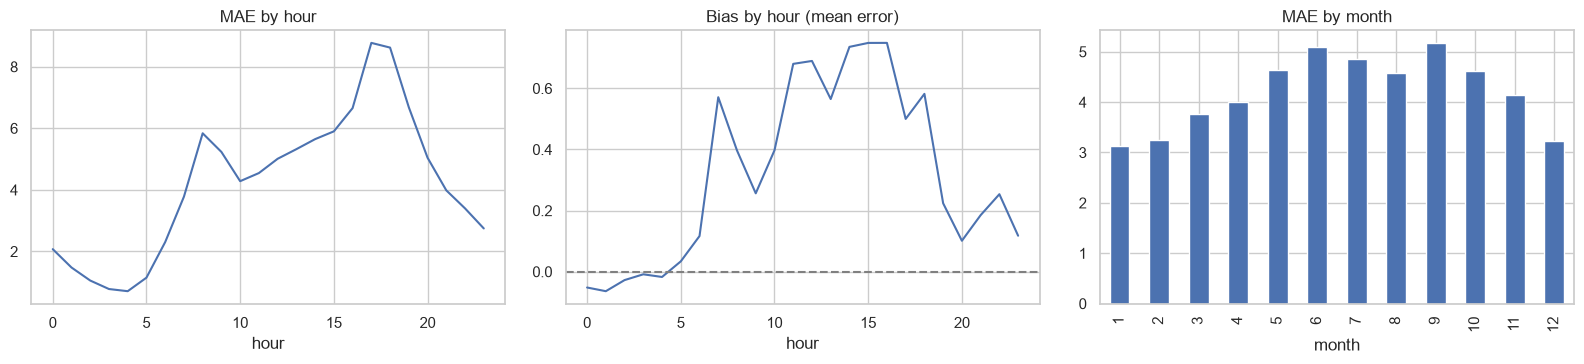

In [12]:
res = test[["ts", "station", "hour", "month", "dayofweek", "is_holiday"]].copy()
if "cluster" in test.columns: res["cluster"] = test["cluster"]
res["actual"], res["pred"] = test[TARGET].values, pred
res["err"] = res.pred - res.actual
res["abs_err"] = res.err.abs()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
res.groupby("hour")[["abs_err"]].mean().plot(ax=ax[0], title="MAE by hour", legend=False)
res.groupby("hour")[["err"]].mean().plot(ax=ax[1], title="Bias by hour (mean error)", legend=False)
ax[1].axhline(0, color="grey", ls="--")
res.groupby("month")[["abs_err"]].mean().plot(kind="bar", ax=ax[2], title="MAE by month", legend=False)
plt.tight_layout(); plt.show()

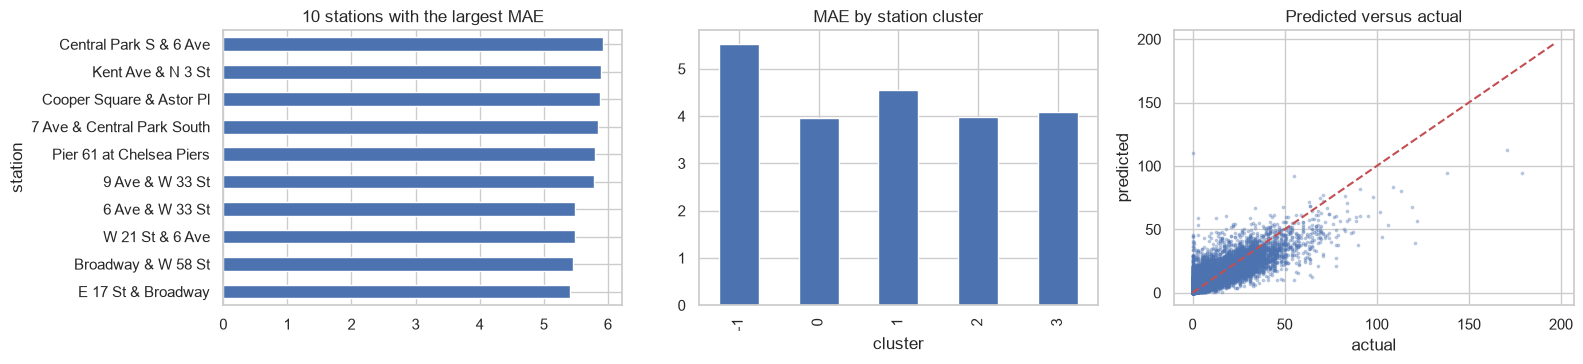

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
res.groupby("station", observed=True)["abs_err"].mean().sort_values().tail(10).plot(kind="barh", ax=ax[0], title="10 stations with the largest MAE")
if "cluster" in res:
    res.groupby("cluster")["abs_err"].mean().plot(kind="bar", ax=ax[1], title="MAE by station cluster")
ax[2].scatter(res.sample(min(20_000, len(res)), random_state=1).actual, res.sample(min(20_000, len(res)), random_state=1).pred, s=3, alpha=.3)
lim = res.actual.max(); ax[2].plot([0, lim], [0, lim], "r--"); ax[2].set_xlabel("actual"); ax[2].set_ylabel("predicted"); ax[2].set_title("Predicted versus actual")
plt.tight_layout(); plt.show()

### The worst days
Add up all stations per day and compare actual with predicted. Days with a big miss in the *same direction at every station* point to something our features cannot see, such as weather or events.

,weekday,holiday,actual,pred,error,error %
ts,,,,,,
2026-09-27,Sun,0,5907,30413.0,24506.0,415.0
2026-09-26,Sat,0,12641,35775.0,23134.0,183.0
2025-10-30,Thu,0,15840,38116.0,22276.0,141.0
2026-05-23,Sat,0,9799,28969.0,19170.0,196.0
2026-07-06,Mon,0,12722,30748.0,18026.0,142.0
2026-05-24,Sun,0,8250,24902.0,16652.0,202.0
2026-02-23,Mon,0,0,16581.0,16581.0,inf
2025-11-28,Fri,0,10874,26918.0,16044.0,148.0
2026-04-25,Sat,0,7460,22899.0,15439.0,207.0


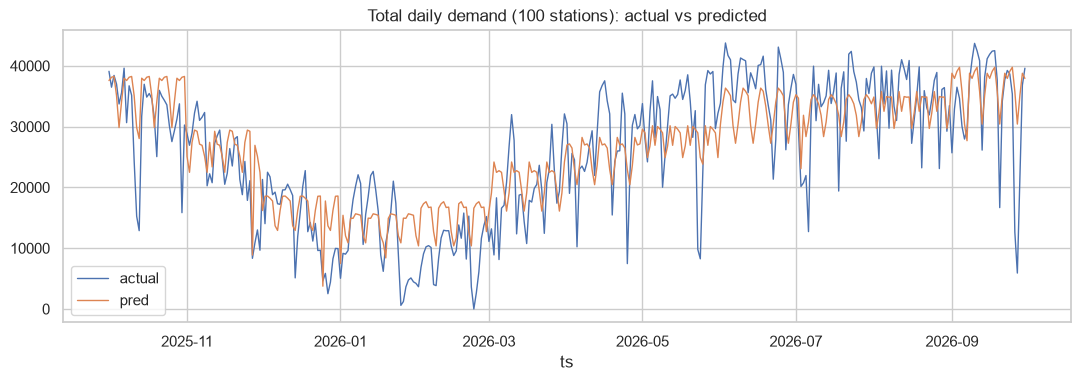

In [14]:
daily = res.groupby(res.ts.dt.date).agg(actual=("actual", "sum"), pred=("pred", "sum"),
                                         dow=("dayofweek", "first"), holiday=("is_holiday", "first"))
daily["error"] = daily.pred - daily.actual
daily["error %"] = (100 * daily.error / daily.actual).round(1)
worst = daily.reindex(daily.error.abs().sort_values(ascending=False).index).head(10)
worst["weekday"] = worst.dow.map(dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])))
display(worst[["weekday", "holiday", "actual", "pred", "error", "error %"]].round(0))

daily[["actual", "pred"]].plot(figsize=(13, 3.8), title="Total daily demand (100 stations): actual vs predicted", lw=1)
plt.show()

**Look these dates up** (weather history for New York: rain, snow, a heat wave? a big event? a public holiday our calendar does not include?). If the worst days are bad-weather days and the model over-predicts them, that is strong evidence that **weather is the most valuable missing feature**, and it tells us exactly where the remaining error comes from.

### Feature importance

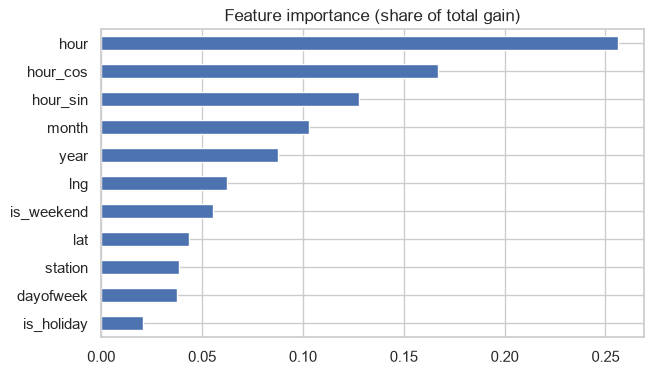

In [15]:
imp = pd.Series(final.get_booster().get_score(importance_type="gain"))
imp.index = [BEST_FEATS[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k for k in imp.index]
(imp / imp.sum()).sort_values().plot(kind="barh", figsize=(7, 4), title="Feature importance (share of total gain)")
plt.show()

**Conclusions (rewrite in your own words after running):**
- What did the complexity curves show? Where did the final settings end up (depth, number of trees, learning rate)?
- Which objective won and why might that be (counts, skew, MAE versus mean)?
- Did the cluster feature help? By how much, and is that more than noise?
- By how much does the tuned model beat the FLAML model from 05 on validation? Is the improvement worth the extra effort?
- What are the biggest remaining errors (hours, stations, days) and what would fix them (weather, events)?